# Cellpose

Fine-tunes the ImageGrains CNN on the same tile archive, the same folds and the
same crops as Cellpose-SAM, so the two runs differ only in the backbone.

Cellpose 2 would resize every crop to the 17 px diameter it was trained on,
which needs more source pixels than a 384 px crop has. Rescaling is therefore
off and the net is fine-tuned at the native 35 px.

Every fold writes `results/cellpose_unet_<fold>.json` as soon as it is done, and
a fold whose file is already there is skipped.

In [1]:
import sys, json, time, re, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from cellpose import models, transforms, core

warnings.filterwarnings("ignore")
root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import config
from common import tiles, crops, evaluate, folds

FOLDS = ["fold1", "fold2", "fold3", "fold4"]
EPOCHS = 150
PER_EPOCH = 250              # crops drawn per epoch, as in the Cellpose-SAM run
BATCH = 8
LR = 0.2                     # cellpose 2 trains with SGD
WEIGHT_DECAY = 1e-5
GAIN = (0.8, 1.25)           # contrast jitter
OFFSET = (-0.1, 0.1)
SAVE_EVERY = 20
SAMPLE = 50                  # tiles used for the checkpoint curve
BASE = config.MODELS / "IG2_full_set.200525"

print("gpu:", torch.cuda.get_device_name(0))
print("base model:", BASE.name, "-", BASE.exists())

gpu: Quadro RTX 5000
base model: IG2_full_set.200525 - True


## Tiles per fold

Validation is one fold, training is everything else except the test block. The
test block stays untouched until the very end.

In [2]:
idx = pd.DataFrame(tiles.read_index())
print(idx.groupby("fold").agg(tiles=("name", "size"), boulders=("n_inner", "sum")))
print(f"\ntest block held back: {int((idx.fold == 'test').sum())} tiles")

              tiles  boulders
fold                         
always_train    382       855
fold1           286       440
fold2           192       471
fold3           207       408
fold4           186       479
test            296       471

test block held back: 296 tiles


## Crops

One crop centred on each boulder plus 30 % random corridor positions. Tiles
without labels are left out, their background is already in every other crop.

In [3]:
def crop_sets(fold):
    train_names = idx.loc[idx.fold.isin(folds.training_folds(fold))
                          & (idx.n_inner > 0), "name"].tolist()
    val_names = idx.loc[(idx.fold == fold) & (idx.n_inner > 0), "name"].tolist()
    xtr, ytr = crops.build(train_names, seed=0, verbose=False)
    xva, yva = crops.build(val_names, seed=1, verbose=False)
    xtr = [a.astype(np.float32) for a in xtr]
    xva = [a.astype(np.float32) for a in xva]
    return xtr, ytr, xva, yva, val_names

## What the crops look like

fold1: 3133 training crops, 626 validation crops, 150 validation tiles


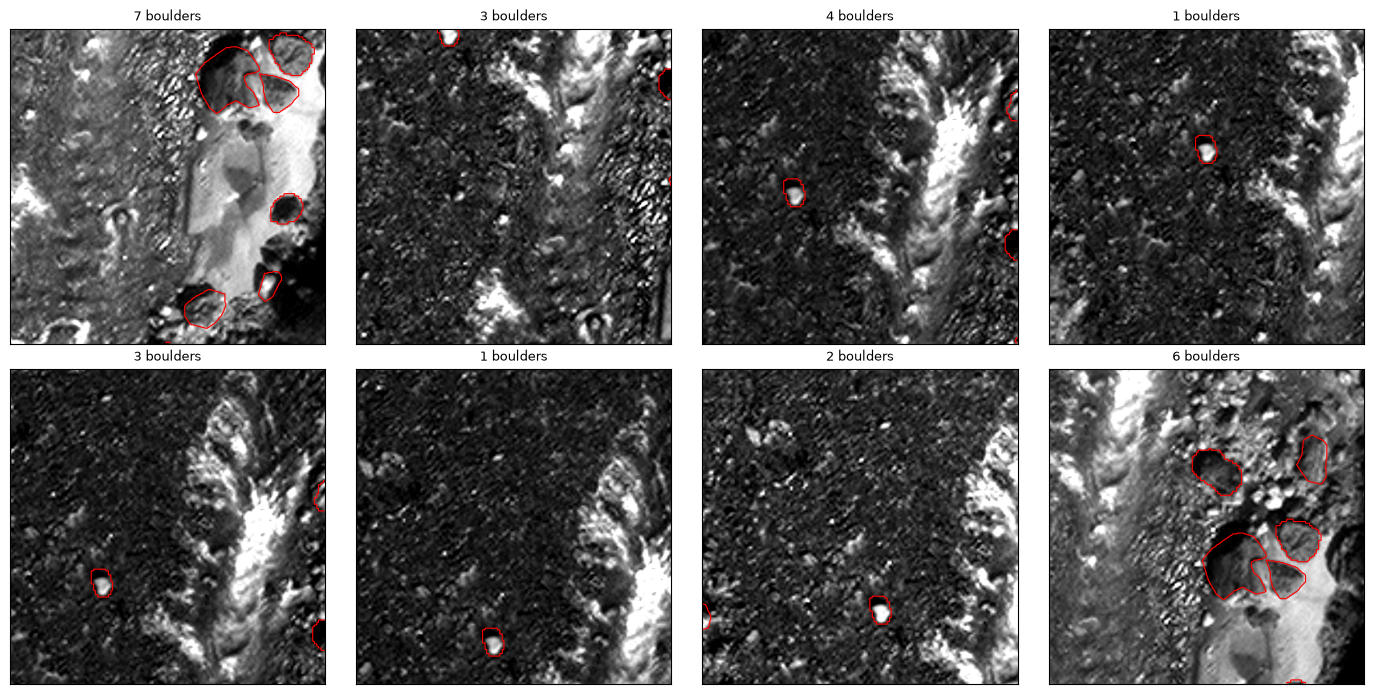

In [4]:
xtr, ytr, xva, yva, val_names = crop_sets(FOLDS[0])
print(f"{FOLDS[0]}: {len(xtr)} training crops, {len(xva)} validation crops, "
      f"{len(val_names)} validation tiles")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (a, b) in zip(axes.ravel(), zip(xtr[:8], ytr[:8])):
    lo, hi = np.percentile(a[a > 0], config.PERCENTILE)
    ax.imshow(np.clip((a - lo) / max(hi - lo, 1), 0, 1), cmap="gray")
    ax.contour(b > 0, levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{int(b.max())} boulders", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## Train and score

On top of cellpose's own rotation, flipping and scaling, every crop is drawn
with a random gain and offset on the grey values, the same jitter the
Cellpose-SAM run uses. The learning rate follows the same schedule as well:
warm up over ten epochs, hold, then halve ten times over the last fifty.

Checkpoints every 20 epochs. Cellpose has no early stopping, so all of them get
scored on a sample of the validation tiles and the best one is then scored on
all of them.

Scoring runs on whole tiles, not crops, because that is how it gets applied.
Only objects whose centre falls inside the corridor and inside the tile's own
inner region count, so nothing is scored twice and nothing on ground that was
never inspected.

In [5]:
# cellpose has no hook for contrast augmentation, so the function it looks up at
# call time is replaced. the grey values live in channel 0, channel 1 is empty
# for single band input. the flow targets are passed through untouched.
_rotate = transforms.random_rotate_and_resize


def rotate_and_jitter(*args, **kwargs):
    imgs, lbls, scale = _rotate(*args, **kwargs)
    rng = np.random.default_rng()
    g = rng.uniform(*GAIN, size=(imgs.shape[0], 1, 1)).astype(np.float32)
    o = rng.uniform(*OFFSET, size=(imgs.shape[0], 1, 1)).astype(np.float32)
    imgs[:, 0] = imgs[:, 0] * g + o
    return imgs, lbls, scale


transforms.random_rotate_and_resize = rotate_and_jitter


# cellpose 2 decays the learning rate only above 250 epochs, cellpose 4 above
# 99. this is the schedule cellpose 4 builds: warm up, hold, then halve ten
# times over the last fifty epochs.
def lr_schedule(epochs, lr):
    s = np.linspace(0, lr, 10)
    s = np.append(s, lr * np.ones(max(0, epochs - 10)))
    s = s[:-50]
    for _ in range(10):
        s = np.append(s, s[-1] / 2 * np.ones(5))
    return list(s)


def _mode(x):
    """scipy.stats.mode returns a scalar now, cellpose 2.3.2 indexes it twice"""
    values, counts = np.unique(np.asarray(x), return_counts=True)
    return (np.array([values[counts.argmax()]]),)


core.mode = _mode


class Losses(logging.Handler):
    """cellpose 2 logs the losses instead of returning them"""
    line = re.compile(r"Epoch (\d+), Time .*?, Loss ([\d.]+)"
                      r"(?:, Loss Test ([\d.]+))?")

    def __init__(self):
        super().__init__()
        self.epoch, self.train, self.test = [], [], []

    def emit(self, record):
        m = self.line.search(record.getMessage())
        if m:
            self.epoch.append(int(m.group(1)))
            self.train.append(float(m.group(2)))
            self.test.append(float(m.group(3)) if m.group(3) else 0.0)

In [6]:
def train_fold(fold, xtr, ytr, xva, yva):
    out = config.MODELS / f"cellpose_unet_{fold}"
    out.mkdir(parents=True, exist_ok=True)
    net = models.CellposeModel(gpu=True, pretrained_model=str(BASE))
    losses = Losses()
    logger = logging.getLogger("cellpose.core")
    logger.setLevel(logging.INFO)
    logger.addHandler(losses)
    try:
        net.train(train_data=xtr, train_labels=ytr,
                  test_data=xva, test_labels=yva,
                  channels=[0, 0], normalize=True,
                  batch_size=BATCH, n_epochs=EPOCHS, nimg_per_epoch=PER_EPOCH,
                  learning_rate=lr_schedule(EPOCHS, LR),
                  weight_decay=WEIGHT_DECAY,
                  rescale=False, min_train_masks=1,
                  save_path=str(out), save_every=SAVE_EVERY, save_each=True,
                  model_name=fold)
    finally:
        logger.removeHandler(losses)
    return out, losses


def predict_tile(model, name):
    img, true, valid = crops.read_tile(name)
    pred, _, _ = model.eval(img.astype(np.float32), channels=[0, 0],
                            diameter=float(model.diam_mean), normalize=True,
                            flow_threshold=0.4, cellprob_threshold=0.0,
                            min_size=15)
    keep = valid.astype(bool) & evaluate.inner_mask(img.shape)
    return evaluate.restrict(pred.astype(np.uint16), keep), evaluate.restrict(true, keep)


def score_checkpoint(ckpt, names):
    model = models.CellposeModel(gpu=True, pretrained_model=str(ckpt))
    rows = [evaluate.score(*predict_tile(model, n)) for n in names]
    del model
    torch.cuda.empty_cache()
    return evaluate.summarise(rows)

In [7]:
config.RESULTS.mkdir(parents=True, exist_ok=True)
started = time.time()

for fold in FOLDS:
    print(f"\n=== {fold} ===", flush=True)
    done = config.RESULTS / f"cellpose_unet_{fold}.json"
    if done.exists():
        print("already scored, skipped", flush=True)
        continue

    t0 = time.time()
    if fold == FOLDS[0]:
        a, b, c, d, names = xtr, ytr, xva, yva, val_names
    else:
        a, b, c, d, names = crop_sets(fold)
    print(f"{len(a)} training crops, {len(c)} validation crops, "
          f"{len(names)} validation tiles", flush=True)

    out, losses = train_fold(fold, a, b, c, d)
    print(f"trained in {(time.time() - t0) / 3600:.2f} h", flush=True)

    # the index runs scene by scene, so the sample has to step through it
    sample = names[:: max(1, len(names) // SAMPLE)][:SAMPLE]
    curve = []
    for ck in sorted((out / "models").glob(f"{fold}*")):
        s = score_checkpoint(ck, sample)
        s["checkpoint"] = ck.name
        curve.append(s)
        print(f"  {ck.name:28} AP {s['ap']:.3f}  P {s['precision']:.3f}  "
              f"R {s['recall']:.3f}", flush=True)

    best = max(curve, key=lambda s: s["ap"])["checkpoint"]
    final = score_checkpoint(out / "models" / best, names)
    print(f"  best {best}: AP {final['ap']:.3f} on all {len(names)} tiles", flush=True)

    json.dump(dict(model="cellpose_unet", fold=fold, base=BASE.name,
                   epochs=EPOCHS, per_epoch=PER_EPOCH, batch=BATCH, lr=LR,
                   res=config.RES, crop=crops.SIZE, rescale=False,
                   n_train_crops=len(a), n_val_crops=len(c),
                   n_val_tiles=len(names), best_checkpoint=best,
                   hours=round((time.time() - t0) / 3600, 2),
                   epoch=losses.epoch, train_loss=losses.train,
                   test_loss=losses.test, curve=curve, **final),
              open(done, "w"), indent=1)

print(f"\nall folds done in {(time.time() - started) / 3600:.1f} h")


=== fold1 ===


3133 training crops, 626 validation crops, 150 validation tiles


  0%|          | 0/3133 [00:00<?, ?it/s]

  0%|          | 3/3133 [00:00<02:02, 25.56it/s]

  0%|          | 8/3133 [00:00<01:33, 33.41it/s]

...

  fold4_epoch_41               AP 0.426  P 0.815  R 0.472


  fold4_epoch_61               AP 0.404  P 0.671  R 0.505


  fold4_epoch_81               AP 0.425  P 0.730  R 0.505


  best fold4_epoch_21: AP 0.493 on all 116 tiles



all folds done in 11.7 h


## Results

Every boulder in the four folds was predicted exactly once, by a model that
never saw it. Cellpose 2 logs the losses instead of returning them and this run
did not keep them, so the figure shows the checkpoint curve only. The pooled numbers add up TP, FP and FN across the folds rather
than averaging the APs, which would give small folds too much weight.

In [7]:
runs = [json.loads(f.read_text()) for f in
        sorted(config.RESULTS.glob("cellpose_unet_fold*.json"))]

keep = ["fold", "tp", "fp", "fn", "ap", "precision", "recall", "mean_iou",
        "d50_pred", "d50_true", "d84_pred", "d84_true", "size_bias", "hours"]
per_fold = pd.DataFrame([{k: r[k] for k in keep} for r in runs]).set_index("fold")

tp, fp, fn = (int(per_fold[c].sum()) for c in ("tp", "fp", "fn"))
dp = np.concatenate([r["d_pred"] for r in runs])
dt = np.concatenate([r["d_true"] for r in runs])

per_fold.loc["pooled"] = {
    "tp": tp, "fp": fp, "fn": fn,
    "ap": tp / (tp + fp + fn),
    "precision": tp / (tp + fp),
    "recall": tp / (tp + fn),
    "mean_iou": np.average(per_fold.mean_iou, weights=per_fold.tp),
    "d50_pred": np.median(dp), "d84_pred": np.percentile(dp, 84),
    "d50_true": np.median(dt), "d84_true": np.percentile(dt, 84),
    "size_bias": np.average(per_fold.size_bias, weights=per_fold.tp),
    "hours": per_fold["hours"].sum()}
per_fold.round(3)

,tp,fp,fn,ap,precision,recall,mean_iou,d50_pred,d50_true,d84_pred,d84_true,size_bias,hours
fold,,,,,,,,,,,,,
fold1,262,72,175,0.515,0.784,0.600,0.778,4.297,4.354,5.514,5.601,-0.128,2.70
fold2,305,64,166,0.570,0.827,0.648,0.788,4.735,4.896,6.444,6.631,-0.200,3.30
fold3,248,74,156,0.519,0.770,0.614,0.785,4.413,4.523,5.719,6.069,-0.168,3.05
fold4,263,55,215,0.493,0.827,0.550,0.779,4.729,4.598,6.460,6.227,-0.118,2.66
pooled,1078,265,712,0.525,0.803,0.602,0.783,4.562,4.599,6.097,6.106,-0.155,11.71


In [8]:
ap = per_fold.ap.drop("pooled")
print(f"AP per fold {ap.min():.3f} to {ap.max():.3f}, pooled {per_fold.ap['pooled']:.3f}")
print(f"precision {per_fold.precision['pooled']:.3f}, "
      f"recall {per_fold.recall['pooled']:.3f}, "
      f"mean IoU {per_fold.mean_iou['pooled']:.3f}")
print(f"D50 {per_fold.d50_pred['pooled']:.2f} m predicted against "
      f"{per_fold.d50_true['pooled']:.2f} m mapped, "
      f"bias {per_fold.size_bias['pooled']:+.2f} m")

AP per fold 0.493 to 0.570, pooled 0.525
precision 0.803, recall 0.602, mean IoU 0.783
D50 4.56 m predicted against 4.60 m mapped, bias -0.15 m


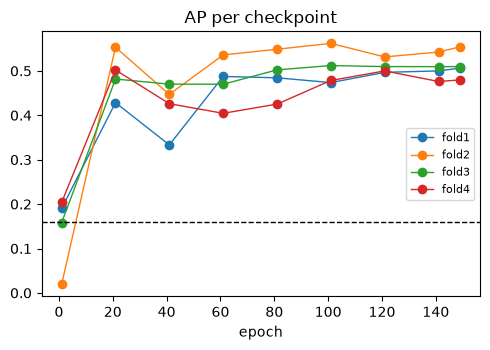

In [9]:
# the final model carries no epoch in its name
def epoch_of(checkpoint):
    tail = checkpoint.rsplit("_", 1)[-1]
    return int(tail) if tail.isdigit() else EPOCHS


has_loss = any(r["train_loss"] for r in runs)
panels = 3 if has_loss else 1
fig, axes = plt.subplots(1, panels, figsize=(5 * panels, 3.6), squeeze=False)
axes = axes[0]

for r in runs:
    if has_loss:
        axes[0].plot(r["epoch"], r["train_loss"], lw=1, label=r["fold"])
        t = np.array(r["test_loss"], float)
        e = np.nonzero(t > 0)[0]
        axes[1].plot(np.array(r["epoch"])[e], t[e], "o-", lw=1.4, ms=3,
                     label=r["fold"])
    curve = sorted(r["curve"], key=lambda c: epoch_of(c["checkpoint"]))
    axes[-1].plot([epoch_of(c["checkpoint"]) for c in curve],
                  [c["ap"] for c in curve], "o-", lw=1, label=r["fold"])

if has_loss:
    axes[0].set_title("training loss")
    axes[1].set_title("validation loss, every tenth epoch")
axes[-1].set_title("AP per checkpoint")
axes[-1].axhline(0.16, color="k", ls="--", lw=1)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

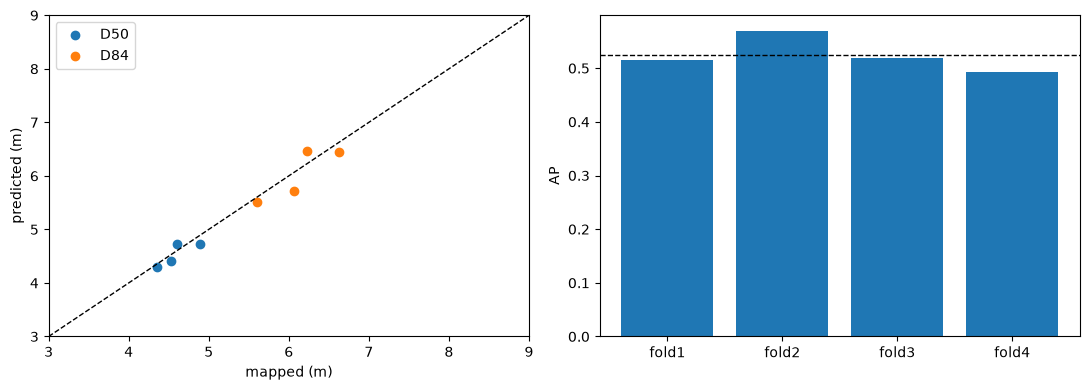

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(per_fold.d50_true.drop("pooled"), per_fold.d50_pred.drop("pooled"),
                label="D50")
axes[0].scatter(per_fold.d84_true.drop("pooled"), per_fold.d84_pred.drop("pooled"),
                label="D84")
lim = [3, 9]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlim(lim)
axes[0].set_ylim(lim)
axes[0].set_xlabel("mapped (m)")
axes[0].set_ylabel("predicted (m)")
axes[0].legend()

axes[1].bar(ap.index, ap.values)
axes[1].axhline(per_fold.ap["pooled"], color="k", ls="--", lw=1)
axes[1].set_ylabel("AP")
plt.tight_layout()
plt.show()

## Predictions against the hand drawn outlines

Red is drawn by hand, green is predicted, orange is the inner region.
Only objects whose centre falls inside it are counted here, the ones in
the border strip belong to the neighbouring tile.

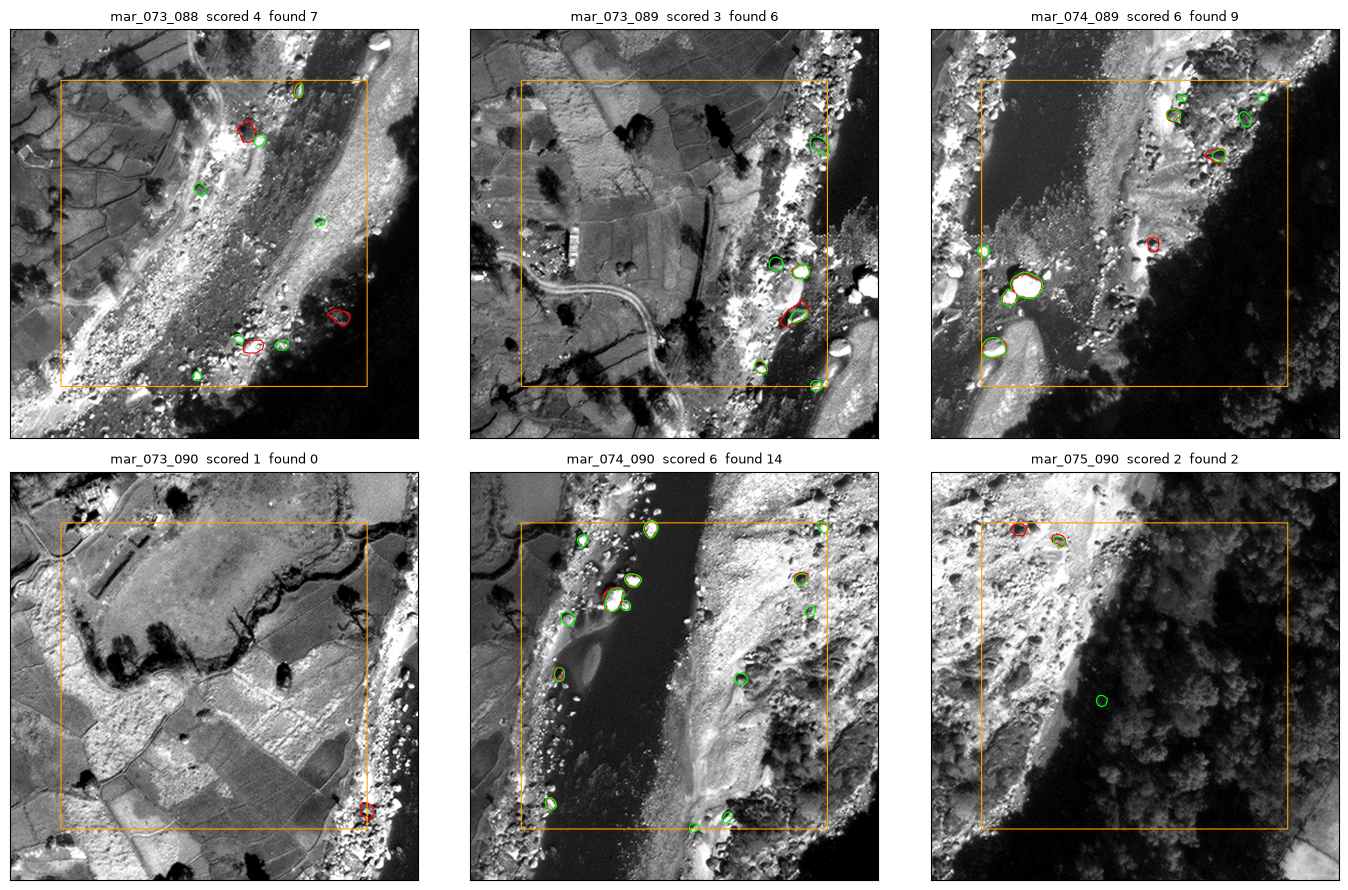

In [11]:
model = models.CellposeModel(
    gpu=True,
    pretrained_model=str(config.MODELS / f"cellpose_unet_{FOLDS[0]}" / "models"
                         / runs[0]["best_checkpoint"]))

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, name in zip(axes.ravel(), val_names[:6]):
    img, _, _ = crops.read_tile(name)
    p, t = predict_tile(model, name)
    lo, hi = np.percentile(img[img > 0], config.PERCENTILE)
    ax.imshow(np.clip((img - lo) / max(hi - lo, 1), 0, 1), cmap="gray")
    ax.contour(t > 0, levels=[0.5], colors="red", linewidths=0.8)
    ax.contour(p > 0, levels=[0.5], colors="lime", linewidths=0.8)
    ax.contour(evaluate.inner_mask(img.shape), levels=[0.5],
               colors="orange", linewidths=0.8)
    ax.set_title(f"{name}  scored {int(t.max())}  found {int(p.max())}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()